In [1]:
import wandb
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
api = wandb.Api(api_key='4a3e44e53460799e4aae1531c4bdfbd4e22f82ce')
path = 'kprotopapas/rl_experiments'

In [2]:
alg = 'dpqa'
div = 'KL' if alg == 'deqa' else 'Euclidean'
metric = 'samples'
inexact = True
n = 15
limit = 90
runs = api.runs(path=path, filters={'group': f'{alg}_v1_inexact'})
dfs = {d: [] for d in [1, 5, 10, 15, 20]}

In [3]:
cutoff = 5 if inexact else 4
for run in runs:
    temp = run.history(keys=[metric], x_axis='_step')\
        .rename(columns={'_step': 'k', metric: f'{metric}_{run.id}'})
    depth = int(run.config['algorithm'][:-cutoff])
    if len(dfs[depth]) > 1:
        continue
    if len(temp) > 80:    
        temp = temp.set_index('k')
        dfs[depth].append(temp)
    

In [ ]:
dfs_small = {k: v[:n] for k, v in dfs.items()}
joined = {k: pd.concat(v, axis=1) for k, v in dfs_small.items()}
stds = {k: v.std(axis=1).rename(f'{k}-std') for k, v in joined.items()}
means = {k: v.mean(axis=1).rename(f'{k}-mean') for k, v in joined.items()}
means_df = pd.concat(means.values(), axis=1).iloc[:limit]
stds_df = pd.concat(stds.values(), axis=1).iloc[:limit]
means_df = means_df - means_df.min()

NameError: name 'means_df' is not defined

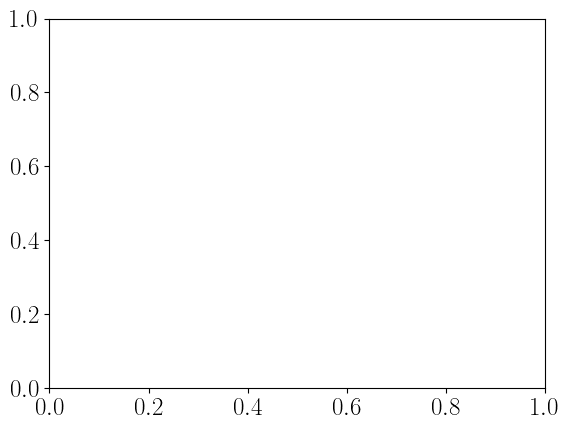

In [4]:
import matplotlib.pyplot as plt
# choose a large font size by default and use tex for math
fontsize = 18
params = {'axes.labelsize': fontsize + 2,
      'font.size': fontsize + 2,
      'legend.fontsize': fontsize + 2,
      'xtick.labelsize': fontsize,
      'ytick.labelsize': fontsize,
      'text.usetex': True}
plt.rcParams.update(params)
plt.rc('font', family='Times New Roman')
fig, ax = plt.subplots()
ax.plot(means_df)
for name, col in stds_df.items():
    depth = int(name[:-4])
    mean_name = f'{depth}-mean'
    mean = means_df[mean_name]
    ax.fill_between(col.index, mean - col, mean + col, alpha=0.2)
    ax.grid(visible=True)

ax.set_xlabel('Iteration')
ax.set_ylabel('')
legends = [f'$h$={depth}' for depth in [1, 5, 10, 15, 20]]
ax.legend(legends)
plt.subplots_adjust(bottom=0.15)
plt.savefig(f'{alg}_samples.pdf')